In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

RANDOM_STATE = 0

In [2]:
# Load dataset

In [3]:
df = pd.read_csv('../data/clean/cleaned_dataframe.csv')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            61069 non-null  int64  
 1   class                 61069 non-null  str    
 2   cap-color             61069 non-null  str    
 3   cap-shape             61069 non-null  str    
 4   does-bruise-or-bleed  61069 non-null  str    
 5   gill-color            61069 non-null  str    
 6   has-ring              61069 non-null  str    
 7   season                61069 non-null  str    
 8   habitat               61069 non-null  str    
 9   cap-diameter          61069 non-null  float64
 10  stem-height           61069 non-null  float64
 11  stem-width            61069 non-null  float64
dtypes: float64(3), int64(1), str(8)
memory usage: 5.6 MB


In [5]:
# Drop Unnamed column
df = df.drop(columns="Unnamed: 0")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  str    
 1   cap-color             61069 non-null  str    
 2   cap-shape             61069 non-null  str    
 3   does-bruise-or-bleed  61069 non-null  str    
 4   gill-color            61069 non-null  str    
 5   has-ring              61069 non-null  str    
 6   season                61069 non-null  str    
 7   habitat               61069 non-null  str    
 8   cap-diameter          61069 non-null  float64
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
dtypes: float64(3), str(8)
memory usage: 5.1 MB


In [6]:
# We split the data into train and test

X_mush = df.drop(columns="class")
y_mush = df["class"]

X_train_mush, X_test_mush, y_train_mush, y_test_mush = train_test_split(
    X_mush,
    y_mush,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_mush,
)

print("Training observations:", len(X_train_mush))
print("Test observations:", len(X_test_mush))
print("Training features:", list(X_train_mush.columns))

Training observations: 48855
Test observations: 12214
Training features: ['cap-color', 'cap-shape', 'does-bruise-or-bleed', 'gill-color', 'has-ring', 'season', 'habitat', 'cap-diameter', 'stem-height', 'stem-width']


In [20]:
# Split features by type
numeric_features = ["cap-diameter", 'stem-height', 'stem-width']
nominal_features = [    "cap-color", "cap-shape","does-bruise-or-bleed", "gill-color", "has-ring", "season", "habitat", "cap-diameter", "stem-height", "stem-width"]


In [21]:
# Define the enconder for Nominal features

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_mush[nominal_features])

encoded_train = pd.DataFrame(
    encoder.transform(X_train_mush[nominal_features]),
    columns=encoder.get_feature_names_out(),
    index=X_train_mush.index,
)
display(encoded_train.head())


,cap-color_b,cap-color_e,cap-color_g,cap-color_k,cap-color_l,cap-color_n,cap-color_o,cap-color_p,cap-color_r,cap-color_u,...,stem-width_88.16,stem-width_88.24,stem-width_89.09,stem-width_89.19,stem-width_89.45,stem-width_91.91,stem-width_92.52,stem-width_94.24,stem-width_95.68,stem-width_102.48
1117,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32619,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12883,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
43050,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
20204,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
# Creating a pipeline for Nominal features

nominal_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

print(nominal_pipeline)

Pipeline(steps=[('encoder', OneHotEncoder(handle_unknown='ignore'))])


In [23]:
# Scale Numerical features
scaler = StandardScaler()

scaled_train = pd.DataFrame(
    scaler.fit_transform(X_train_mush[numeric_features]),
    columns=numeric_features,
    index=X_train_mush.index,
)

scaled_test = pd.DataFrame(
    scaler.transform(X_test_mush[numeric_features]),
    columns=numeric_features,
    index=X_test_mush.index,
)

In [24]:
# Creating a pipeline for Numerical features

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', scaler),
])

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [25]:
# Combine nominal and numerical features

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("nominal", nominal_pipeline, nominal_features),
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

model.fit(X_train_mush, y_train_mush)
y_pred = model.predict(X_test_mush)

In [26]:
y_pred

array(['p', 'e', 'p', ..., 'e', 'e', 'p'], shape=(12214,), dtype=object)

              precision    recall  f1-score   support

      Edible       0.99      0.99      0.99      5436
   Poisonous       0.99      0.99      0.99      6778

    accuracy                           0.99     12214
   macro avg       0.99      0.99      0.99     12214
weighted avg       0.99      0.99      0.99     12214



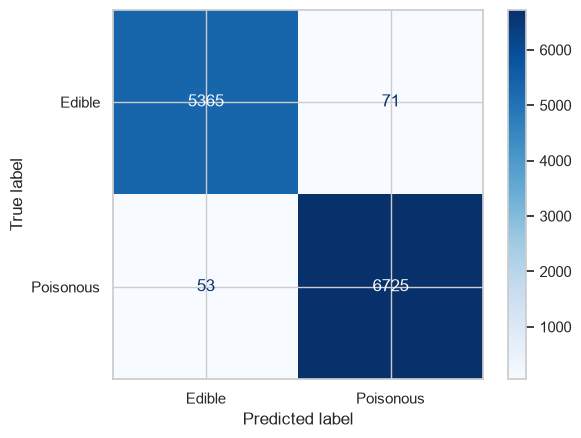

In [27]:
# Evaluate predictions

print(classification_report(
    y_test_mush,
    y_pred,
    labels=["e", "p"],
    target_names=["Edible", "Poisonous"],
))

ConfusionMatrixDisplay.from_predictions(
    y_test_mush,
    y_pred,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"],
    cmap="Blues",
)
plt.show()

In [28]:
# We want to compare the Test and Training models to check if there is overfitting or underfitting

train_accuracy = model.score(X_train_mush, y_train_mush)
test_accuracy = model.score(X_test_mush, y_test_mush)

print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Test accuracy:     {test_accuracy:.2%}")
print(f"Accuracy gap:     {(train_accuracy - test_accuracy) * 100:.2f} percentage points")

Training accuracy: 99.25%
Test accuracy:     98.98%
Accuracy gap:     0.26 percentage points


## Logistic Regression

In [16]:
# Split features by type
numeric_features = ["cap-diameter", "stem-height", "stem-width"]

nominal_features = [
    "cap-color",
    "cap-shape",
    "does-bruise-or-bleed",
    "gill-color",
    "has-ring",
    "season",
    "habitat",
]

In [17]:
# Combine nominal and numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("nominal", nominal_pipeline, nominal_features),
])

In [18]:
#Train logistic regression and make predictions

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])

logistic_model.fit(X_train_mush, y_train_mush)
y_pred_logistic = logistic_model.predict(X_test_mush)

Training accuracy: 68.87%
Test accuracy:     69.39%

Classification report:
              precision    recall  f1-score   support

      Edible       0.67      0.62      0.64      5436
   Poisonous       0.71      0.75      0.73      6778

    accuracy                           0.69     12214
   macro avg       0.69      0.69      0.69     12214
weighted avg       0.69      0.69      0.69     12214



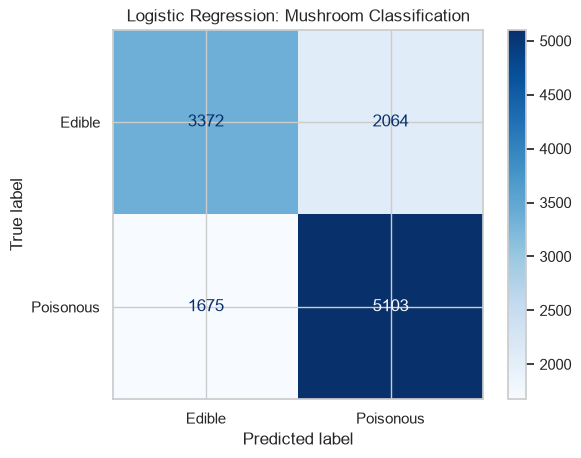

In [19]:
#Check how the model did

train_accuracy = logistic_model.score(X_train_mush, y_train_mush)
test_accuracy = accuracy_score(y_test_mush, y_pred_logistic)

print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Test accuracy:     {test_accuracy:.2%}")

print("\nClassification report:")
print(classification_report(
    y_test_mush,
    y_pred_logistic,
    labels=["e", "p"],
    target_names=["Edible", "Poisonous"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test_mush,
    y_pred_logistic,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"],
    cmap="Blues",
)
plt.title("Logistic Regression: Mushroom Classification")
plt.show()

## Hyperparameter Tuning and Cross Validation

In [29]:
#Get a baseline with cross-validation

from sklearn.model_selection import cross_val_score, GridSearchCV

baseline_scores = cross_val_score(
    logistic_model,
    X_train_mush,
    y_train_mush,
    cv=4,
    scoring="accuracy",
)

print("Accuracy on each fold:", [f"{score:.2%}" for score in baseline_scores])
print(f"Baseline CV accuracy: {baseline_scores.mean():.2%}")

Accuracy on each fold: ['68.44%', '68.99%', '69.26%', '68.57%']
Baseline CV accuracy: 68.81%


In [30]:
#Use Grid Search to try different settings
# C controls how strongly the model's feature weights are kept small.
# Smaller C = stronger restraint; larger C = more freedom.
# C=1 is the original setting, so we try values on both sides of it.
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    refit=True,
    n_jobs=-1,
)

grid_search.fit(X_train_mush, y_train_mush)

cv_gain = (grid_search.best_score_ - baseline_scores.mean()) * 100

print("Best settings:", grid_search.best_params_)
print(f"Tuned CV accuracy: {grid_search.best_score_:.2%}")
print(f"CV change: {cv_gain:+.2f} percentage points")

Best settings: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Tuned CV accuracy: 69.52%
CV change: +0.70 percentage points


Tuned Logistic Regression: Classification Report
              precision    recall  f1-score   support

      Edible     0.6553    0.7103    0.6817      5436
   Poisonous     0.7509    0.7004    0.7247      6778

    accuracy                         0.7048     12214
   macro avg     0.7031    0.7053    0.7032     12214
weighted avg     0.7083    0.7048    0.7056     12214

Tuned test accuracy: 70.48%
Poisonous recall: 70.04%
Poisonous mushrooms predicted edible: 2,031


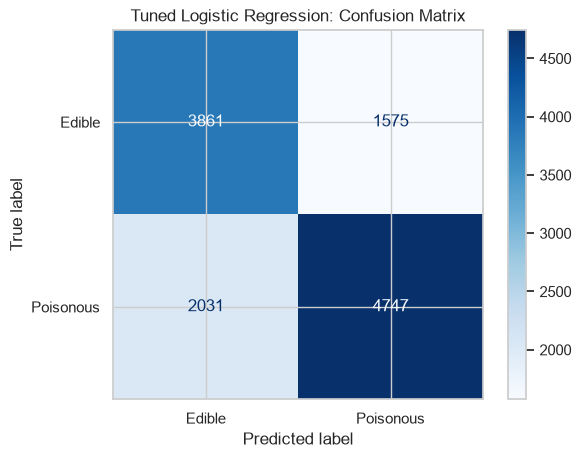

In [33]:
#Check accuracy and count missed poisonous mushrooms
from sklearn.metrics import accuracy_score, confusion_matrix

best_logistic_model = grid_search.best_estimator_
y_pred_tuned = best_logistic_model.predict(X_test_mush)

print("Tuned Logistic Regression: Classification Report")
print(classification_report(
    y_test_mush,
    y_pred_tuned,
    labels=["e", "p"],
    target_names=["Edible", "Poisonous"],
    digits=4,
    zero_division=0,
))
test_accuracy = accuracy_score(y_test_mush, y_pred_tuned)
matrix = confusion_matrix(y_test_mush, y_pred_tuned, labels=["e", "p"])

missed_poisonous = matrix[1, 0]
poisonous_recall = matrix[1, 1] / matrix[1].sum()

print(f"Tuned test accuracy: {test_accuracy:.2%}")
print(f"Poisonous recall: {poisonous_recall:.2%}")
print(f"Poisonous mushrooms predicted edible: {missed_poisonous:,}")

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["Edible", "Poisonous"],
).plot(cmap="Blues", values_format="d")

plt.title("Tuned Logistic Regression: Confusion Matrix")
plt.show()

## Conclusions

We used Logistic Regression to classify mushrooms as edible or poisonous based on ten features from the secondary dataset. We trained the model on 80% of the data and evaluated it on the remaining 20%, using a stratified split to preserve the class proportions. The pipeline scaled the three numerical features and one-hot encoded the categorical features. These preprocessing steps were fitted on the training data and then applied to the test data.

### Model performance

The original Logistic Regression model achieved **69.39% test accuracy** and a **macro F1 score of 0.6876**. It correctly identified **75.29% of poisonous mushrooms**, but classified **1,675 poisonous mushrooms as edible**. This shows why we looked beyond overall accuracy: it tells us how often the model was right, but not which mistakes it made.

### Overfitting and underfitting

The original model achieved **68.87% training accuracy** and **69.39% test accuracy**. The scores were close, with the test score **0.52 percentage points higher**. There was little evidence of substantial overfitting on this split because the model did not perform much better on the training data. Instead, the modest scores on both sets suggest that this Logistic Regression setup may have been too simple to capture some of the patterns in the data.

### Effect of hyperparameter tuning

We used `GridSearchCV` with four-fold cross-validation to test different values of `C` and `class_weight`. The search selected the settings with the highest average validation accuracy. We then evaluated the selected model on the same held-out test set.

| Test metric | Original Logistic Regression | Tuned Logistic Regression |
|---|---:|---:|
| Accuracy | 69.39% | **70.48%** |
| Macro F1 | 0.6876 | **0.7032** |
| Poisonous recall | **75.29%** | 70.04% |
| Poisonous mushrooms predicted as edible | **1,675** | 2,031 |

Tuning improved accuracy by **1.09 percentage points**, but the tuned model missed **356 more poisonous mushrooms**. The accuracy increased because it correctly identified **489 more edible mushrooms**, which outweighed the extra mistakes on the poisonous class. In other words, **the tuned model made fewer mistakes overall, but more of the mistake we cared about most**.

